# Emotion Recognition from Speech (RAVDESS + MFCC + CNN/LSTM)
CodeAlpha Machine Learning Internship, Task 2

In [1]:
!pip install librosa -q

In [2]:
import os
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
from glob import glob
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

tf.random.set_seed(42)
np.random.seed(42)

## 1. Download the dataset\nRAVDESS (speech part): 1,440 audio files from 24 actors (12 male, 12 female) saying two sentences in 8 emotions. The download is about 215 MB and takes a few minutes.

In [3]:
!wget -q -O ravdess.zip "https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip?download=1"
!unzip -q -o ravdess.zip -d /content/ravdess
DATA_DIR = '/content/ravdess'

## 2. Read labels from file names\nA RAVDESS file name like `03-01-06-01-02-01-12.wav` stores the emotion in the 3rd number and the actor in the 7th number.

In [4]:
emotion_map = {1: 'neutral', 2: 'calm', 3: 'happy', 4: 'sad',
               5: 'angry', 6: 'fearful', 7: 'disgust', 8: 'surprised'}

rows = []
for path in glob(DATA_DIR + '/**/*.wav', recursive=True):
    parts = os.path.basename(path).replace('.wav', '').split('-')
    rows.append({'path': path,
                 'emotion': emotion_map[int(parts[2])],
                 'actor': int(parts[6])})

df = pd.DataFrame(rows)
print('Files:', len(df), '| Actors:', df['actor'].nunique())
df['emotion'].value_counts()

Files: 1440 | Actors: 24


,count
emotion,
disgust,192
fearful,192
angry,192
happy,192
surprised,192
calm,192
sad,192
neutral,96


## 3. Look at one audio file

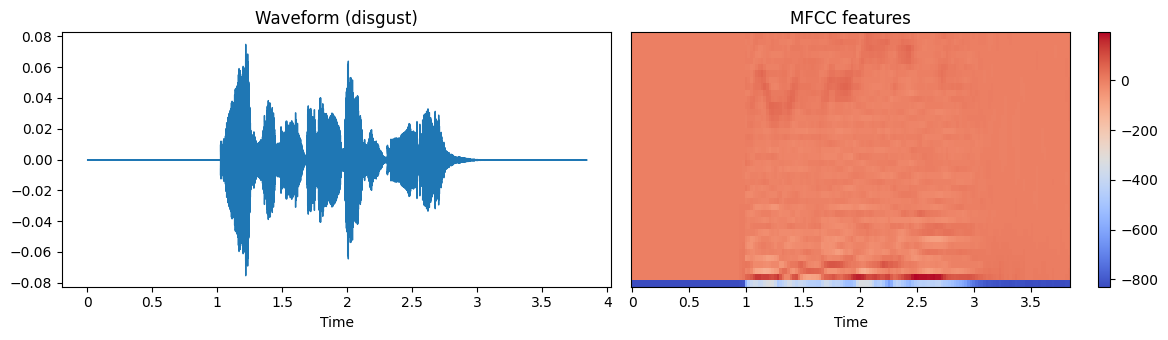

In [5]:
sample = df.iloc[0]
y_audio, sr = librosa.load(sample['path'], sr=22050)
mfcc_demo = librosa.feature.mfcc(y=y_audio, sr=sr, n_mfcc=40)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
librosa.display.waveshow(y_audio, sr=sr, ax=axes[0])
axes[0].set_title('Waveform (' + sample['emotion'] + ')')
img = librosa.display.specshow(mfcc_demo, x_axis='time', ax=axes[1])
axes[1].set_title('MFCC features')
fig.colorbar(img, ax=axes[1])
plt.tight_layout()
plt.show()

## 4. Extract MFCC features\nMFCCs describe the sound of the voice in a compact form. Every file is cut to the same length (3 seconds).

In [6]:
SR = 22050
DURATION = 3
N_MFCC = 40
MAX_LEN = 130   # number of time frames in 3 seconds

def extract_features(path):
    y, sr = librosa.load(path, sr=SR, duration=DURATION, offset=0.5)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC).T   # (time, 40)
    if mfcc.shape[0] < MAX_LEN:
        mfcc = np.pad(mfcc, ((0, MAX_LEN - mfcc.shape[0]), (0, 0)))
    else:
        mfcc = mfcc[:MAX_LEN]
    return mfcc

X = np.array([extract_features(p) for p in df['path']])
le = LabelEncoder()
y = le.fit_transform(df['emotion'])
print('Feature shape:', X.shape)
print('Classes:', list(le.classes_))

Feature shape: (1440, 130, 40)
Classes: ['angry', 'calm', 'disgust', 'fearful', 'happy', 'neutral', 'sad', 'surprised']


## 5. Split by actor\nThe same actor says the same sentences in every emotion. If one actor appears in both train and test, the model can memorize the voice and the score looks too high. So actors 1 to 20 are used for training and actors 21 to 24 for testing. The model never hears the test voices during training.

In [7]:
train_mask = (df['actor'] <= 20).values
X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[~train_mask], y[~train_mask]
print('Train files:', len(X_train), '| Test files:', len(X_test))

mean = X_train.mean(axis=(0, 1), keepdims=True)
std = X_train.std(axis=(0, 1), keepdims=True) + 1e-8
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

Train files: 1200 | Test files: 240


## 6. Build two models: CNN and LSTM

In [8]:
def build_cnn():
    return keras.Sequential([
        layers.Input(shape=(MAX_LEN, N_MFCC)),
        layers.Conv1D(64, 5, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Dropout(0.3),
        layers.Conv1D(128, 5, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Dropout(0.3),
        layers.GlobalAveragePooling1D(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(8, activation='softmax'),
    ])

def build_lstm():
    return keras.Sequential([
        layers.Input(shape=(MAX_LEN, N_MFCC)),
        layers.LSTM(128),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(8, activation='softmax'),
    ])

builders = {'CNN': build_cnn, 'LSTM': build_lstm}
builders['CNN']().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 130, 64)        │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 130, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 65, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 65, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 65, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 65, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 63,496 (248.03 KB)

 Trainable params: 63,112 (246.53 KB)

 Non-trainable params: 384 (1.50 KB)

## 7. Train\nTraining stops early when validation accuracy stops improving, and the best version is kept.

In [9]:
models, histories, results = {}, {}, []

for name, build in builders.items():
    print('Training', name)
    model = build()
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    stop = keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=10,
                                         restore_best_weights=True)
    hist = model.fit(X_train, y_train, epochs=60, batch_size=32,
                     validation_split=0.15, callbacks=[stop], verbose=0)
    pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
    models[name], histories[name] = model, hist
    results.append({'Model': name,
                    'Test Accuracy': accuracy_score(y_test, pred),
                    'Epochs run': len(hist.history['loss'])})

results_df = pd.DataFrame(results).set_index('Model').round(4)
results_df

Training CNN
Training LSTM


,Test Accuracy,Epochs run
Model,,
CNN,0.4292,17
LSTM,0.3542,25


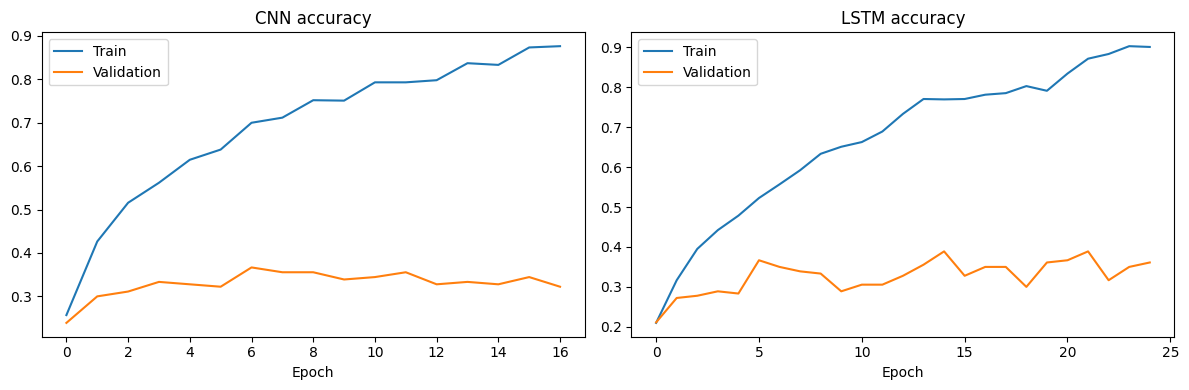

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, hist) in zip(axes, histories.items()):
    ax.plot(hist.history['accuracy'], label='Train')
    ax.plot(hist.history['val_accuracy'], label='Validation')
    ax.set_title(name + ' accuracy')
    ax.set_xlabel('Epoch')
    ax.legend()
plt.tight_layout()
plt.show()

## 8. Evaluate the best model

In [11]:
best = results_df['Test Accuracy'].idxmax()
best_model = models[best]
print('Best model:', best)

y_pred = np.argmax(best_model.predict(X_test, verbose=0), axis=1)
labels = list(range(len(le.classes_)))
print(classification_report(y_test, y_pred, labels=labels,
                            target_names=le.classes_, digits=3, zero_division=0))

Best model: CNN
              precision    recall  f1-score   support

       angry      0.490     0.750     0.593        32
        calm      0.731     0.594     0.655        32
     disgust      0.750     0.188     0.300        32
     fearful      0.667     0.438     0.528        32
       happy      0.235     0.500     0.320        32
     neutral      0.500     0.125     0.200        16
         sad      0.288     0.531     0.374        32
   surprised      1.000     0.156     0.270        32

    accuracy                          0.429       240
   macro avg      0.583     0.410     0.405       240
weighted avg      0.588     0.429     0.419       240



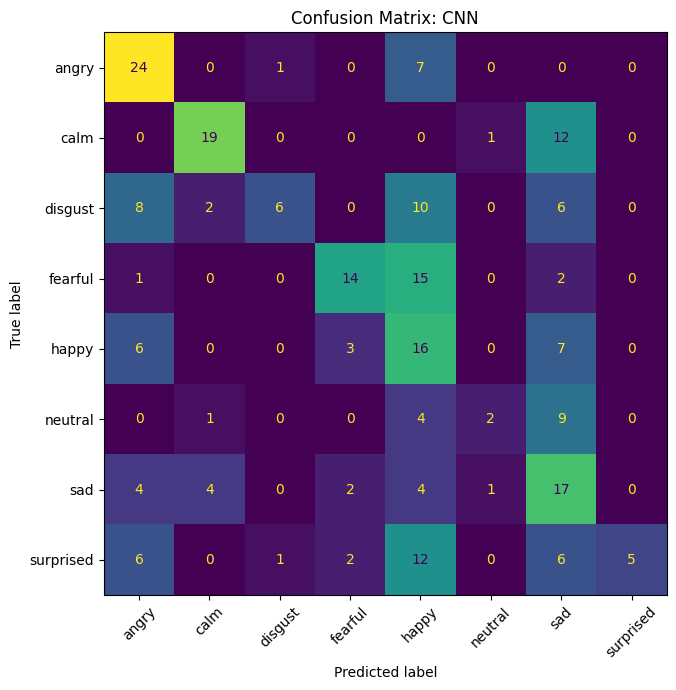

In [12]:
cm = confusion_matrix(y_test, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(ax=ax, colorbar=False, xticks_rotation=45)
plt.title('Confusion Matrix: ' + best)
plt.tight_layout()
plt.show()

## 9. Test with your own voice (optional)\nRecord a short voice clip on your phone (3 seconds, say a sentence with a clear emotion), then upload it here. A wav file works best.

In [13]:
from google.colab import files

uploaded = files.upload()
name = list(uploaded.keys())[0]

feat = extract_features(name)
feat = (feat[np.newaxis, ...] - mean) / std
probs = best_model.predict(feat, verbose=0)[0]

top3 = np.argsort(probs)[::-1][:3]
for i in top3:
    print(le.classes_[i], ':', round(float(probs[i]) * 100, 1), '%')

Saving angry.wav.m4a to angry.wav.m4a


/tmp/ipykernel_3642/53465457.py:7: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(path, sr=SR, duration=DURATION, offset=0.5)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


angry : 93.4 %
happy : 3.0 %
disgust : 2.8 %
